# Parte individual: grafo de colaboración de Margot Robbie

Sofía Isabela Sandoval Vásquez · Análisis y Ciencia de Datos · Universidad del Istmo

El notebook corre de principio a fin sin API key, leyendo las respuestas guardadas en `cache/`.
Para volver a descargar, se pone el key en `tmdb_key.txt` (no se sube al repositorio).

## Uso de inteligencia artificial

Para esta parte se contó con el apoyo de una herramienta de inteligencia artificial (Claude).
Primero se hizo una lectura personal del enunciado y se definió qué pedía cada inciso.
Con esas notas se le pidió apoyo para escribir las clases `Graph` y `TMDBAPIUtils`, el cache
en JSON y el código del espectro (Laplacianos, BFS, clustering espectral y vector de Fiedler),
y para darle formato a las figuras.

Los resultados y las respuestas se analizaron de forma personal, y la herramienta solo ayudó a
mejorar la redacción. Al final se revisó que cada cifra del texto coincida con lo que imprime el notebook.

In [1]:
import json
import re
from collections import Counter, deque
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import requests
from sklearn.cluster import KMeans

ACTOR = 'Margot Robbie'
SEMILLA_KMEANS = 140405
LIMIT = 5
INICIO, FIN = '1975-01-01', '2025-12-31'
Path('figs').mkdir(exist_ok=True)

## I.2 Clase `Graph`

In [2]:
class Graph:
    def __init__(self):
        self.nodes = {}   # id -> name
        self.edges = {}   # (a, b) con a < b -> peso

    def add_node(self, id, name):
        self.nodes.setdefault(id, name)

    def add_edge(self, a, b):
        k = (min(a, b), max(a, b))
        self.edges[k] = self.edges.get(k, 0) + 1

    def total_nodes(self):
        return len(self.nodes)

    def total_edges(self):
        return len(self.edges)

    def max_degree_nodes(self):
        grado = Counter(n for e in self.edges for n in e)
        m = max(grado.values())
        return {n: g for n, g in grado.items() if g == m}

    def adjacency(self):
        ids = list(self.nodes)
        pos = {n: i for i, n in enumerate(ids)}
        A = np.zeros((len(ids), len(ids)))
        for (a, b), w in self.edges.items():
            A[pos[a], pos[b]] = A[pos[b], pos[a]] = w
        return A, ids


# prueba rapida: (1,2) y (2,1) son la misma arista
t = Graph()
for n in (1, 2, 3):
    t.add_node(n, str(n))
t.add_edge(1, 2); t.add_edge(2, 1); t.add_edge(2, 3)
assert t.total_edges() == 2 and t.max_degree_nodes() == {2: 2} and t.adjacency()[0][0, 1] == 2

## I.3 Clase `TMDBAPIUtils`

In [3]:
ES_EL_MISMO = re.compile(r'\b(self|himself|herself|themselves)\b', re.I)


class TMDBAPIUtils:
    URL = 'https://api.themoviedb.org/3'

    def __init__(self, api_key=None, cache='cache'):
        self.api_key = api_key
        self.cache = Path(cache)
        self.cache.mkdir(exist_ok=True)

    def _get(self, ruta, **params):
        nombre = re.sub(r'\W+', '_', ruta + '_' + '_'.join(map(str, params.values()))).strip('_')
        archivo = self.cache / f'{nombre}.json'
        if archivo.exists():
            return json.loads(archivo.read_text())
        if not self.api_key:
            raise RuntimeError(f'no esta {archivo} en el cache y no hay API key')
        r = requests.get(self.URL + ruta, params={'api_key': self.api_key, **params}, timeout=30)
        if not r.ok:  # sin el URL en el mensaje, para no imprimir el key
            raise RuntimeError(f'TMDB respondio {r.status_code} en {ruta}')
        archivo.write_text(r.text)
        return r.json()

    def buscar_persona(self, nombre):
        return self._get('/search/person', query=nombre)['results'][0]

    def get_movie_cast(self, movie_id, limit, exclude_ids=()):
        cast = self._get(f'/movie/{movie_id}/credits')['cast']
        return [c for c in cast if 0 <= c['order'] < limit and c['id'] not in exclude_ids]

    def get_movie_credits_for_person(self, person_id, start_date, end_date):
        nombre = self._get(f'/person/{person_id}')['name'].lower()
        pelis = {}
        for c in self._get(f'/person/{person_id}/movie_credits')['cast']:
            fecha = c.get('release_date') or ''
            if not start_date <= fecha <= end_date:
                continue
            personaje = (c.get('character') or '').lower()
            # se interpreta a si mismo: 'Self', 'Herself' o su propio nombre (p. ej. John Cena en la WWE)
            if 99 in c.get('genre_ids', []) or ES_EL_MISMO.search(personaje) or nombre in personaje:
                continue
            # una persona puede salir dos veces en la misma pelicula: se queda el mejor order
            if c['id'] not in pelis or c['order'] < pelis[c['id']]['order']:
                pelis[c['id']] = {k: c[k] for k in ('id', 'title', 'release_date', 'order')}
        return list(pelis.values())

## I.4 Construcción del grafo

In [4]:
llave = Path('tmdb_key.txt')
api = TMDBAPIUtils(llave.read_text().strip() if llave.exists() else None)


def cuentan(pid):
    return [m for m in api.get_movie_credits_for_person(pid, INICIO, FIN) if m['order'] < LIMIT]


semilla = api.buscar_persona(ACTOR)
g = Graph()
g.add_node(semilla['id'], semilla['name'])

# (b) elenco principal de cada pelicula que cuenta para la semilla
for m in cuentan(semilla['id']):
    for c in api.get_movie_cast(m['id'], LIMIT, {semilla['id']}):
        g.add_node(c['id'], c['name'])

# (c) pelicula -> nodos para los que cuenta; asi cada pareja suma una vez por pelicula
titulos, elenco = {}, {}
for pid in list(g.nodes):
    for m in cuentan(pid):
        titulos[m['id']] = f"{m['title']} ({m['release_date'][:4]})"
        elenco.setdefault(m['id'], set()).add(pid)

for nodos in elenco.values():
    for a, b in combinations(nodos, 2):
        g.add_edge(a, b)

print('nodos:', g.total_nodes(), ' aristas:', g.total_edges())
print('mayor grado:', {g.nodes[n]: d for n, d in g.max_degree_nodes().items()})

nodos: 90  aristas: 370
mayor grado: {'Margot Robbie': 89}


El grafo tiene **90 actores y 370 aristas**. El nodo de mayor grado es Margot Robbie, con grado 89: por construcción está conectada con todos los demás. Le cuentan 26 películas dentro de la ventana.

**Una decisión sobre los papeles propios.** Al revisar el cache apareció John Cena con 238 películas que cuentan, casi todas eventos de la WWE en los que su personaje se llama "John Cena". Eso también es interpretarse a sí mismo, pero no lo atrapa buscar "Self", "Himself" o "Herself". Por eso también se excluyen los papeles en los que el personaje contiene el nombre del actor. En los 90 actores había 170 papeles así.

## I.5 Visualización

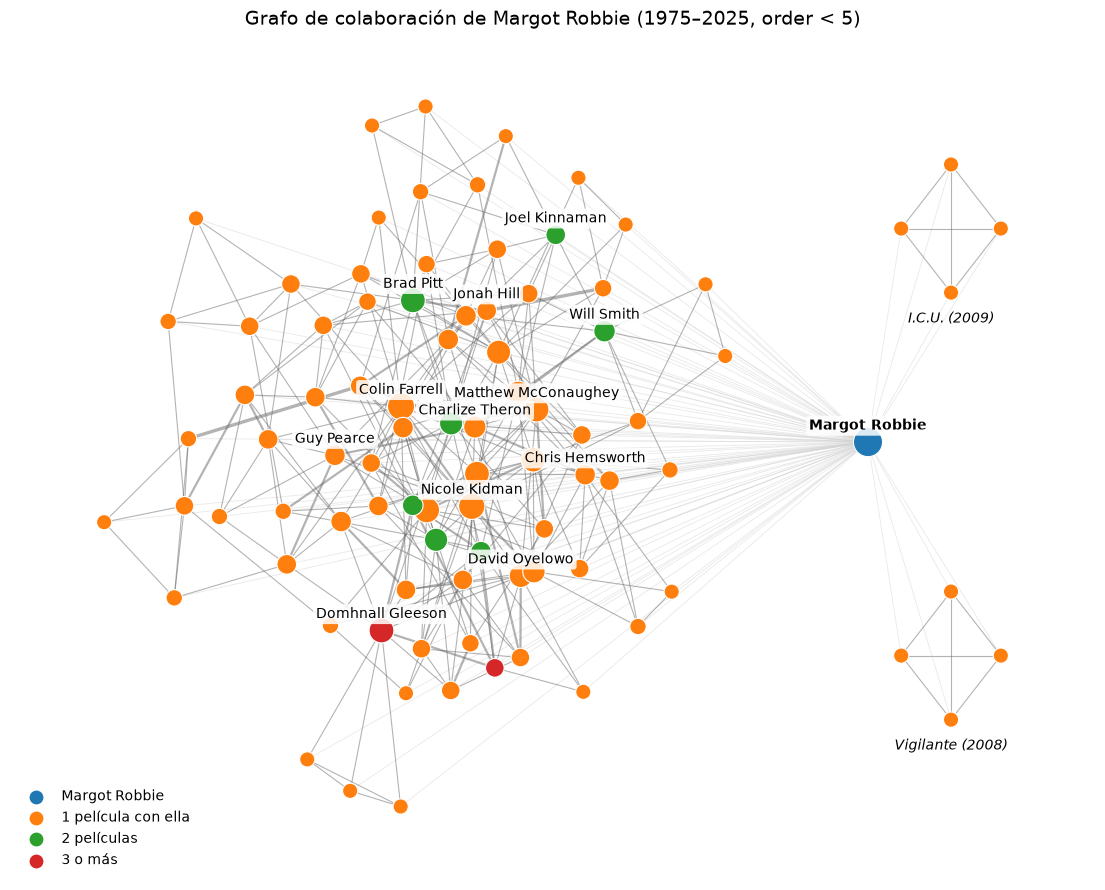

In [5]:
A, ids = g.adjacency()
nombres = np.array([g.nodes[i] for i in ids])
grado = (A > 0).sum(1)
i0 = ids.index(semilla['id'])
G = nx.from_numpy_array(A)

# la semilla toca a todos y aplasta el dibujo en una estrella: se acomoda el resto sin ella y ella va a un lado
resto_ids = [i for i in range(len(ids)) if i != i0]
H = nx.from_numpy_array(np.delete(np.delete(A, i0, 0), i0, 1))
comps = sorted(nx.connected_components(H), key=len, reverse=True)
pos = {}
for j, comp in enumerate(comps):
    escala, centro = (1, (0, 0)) if j == 0 else (0.15, (1.55, 0.5 - (j - 1) * 1.0))
    sub = nx.kamada_kawai_layout(H.subgraph(comp), weight=None, scale=escala, center=centro)
    pos.update({resto_ids[n]: xy for n, xy in sub.items()})
pos[i0] = np.array([1.3, 0.0])
paleta = plt.cm.tab10.colors


def dibujar(grupo, leyenda, archivo, titulo, n_nombres=12):
    fig, ax = plt.subplots(figsize=(14, 11))
    de_semilla = [e for e in G.edges if i0 in e]
    resto = [e for e in G.edges if i0 not in e]
    nx.draw_networkx_edges(G, pos, de_semilla, ax=ax, edge_color='lightgray', alpha=0.5, width=0.6)
    nx.draw_networkx_edges(G, pos, resto, ax=ax, edge_color='dimgray', alpha=0.5,
                           width=[0.8 * G[u][v]['weight'] for u, v in resto])
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=40 + 20 * np.minimum(grado, 20),
                           node_color=[paleta[c] for c in grupo], edgecolors='white', linewidths=0.8)
    top = [i0]
    for i in np.argsort(grado)[::-1]:  # sólo se nombra a quien no tiene otro nombre muy cerca
        if len(top) <= n_nombres and all(np.linalg.norm(pos[i] - pos[j]) > 0.18 for j in top):
            top.append(i)
    for i in top:
        ax.annotate(nombres[i], pos[i], xytext=(0, 9), textcoords='offset points', ha='center', fontsize=10,
                    fontweight='bold' if i == i0 else 'normal',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))
    for comp in comps[1:]:  # titulo de la pelicula que une a cada grupo chico
        mi = {ids[resto_ids[n]] for n in comp}
        m = Counter(m for m, n in elenco.items() for _ in n & mi).most_common(1)[0][0]
        x, y = np.mean([pos[resto_ids[n]] for n in comp], axis=0)
        ax.text(x, y - 0.22, titulos[m], ha='center', fontsize=10, style='italic')
    for c, et in enumerate(leyenda):
        ax.scatter([], [], color=paleta[c], s=80, label=et)
    ax.legend(loc='lower left', fontsize=10, frameon=False)
    ax.set_title(titulo, fontsize=14)
    ax.axis('off')
    fig.savefig(f'figs/{archivo}', dpi=200, bbox_inches='tight')
    plt.show()


# color: cuantas peliculas comparte cada actor con la semilla
con_semilla = np.minimum(A[i0], 3).astype(int)
dibujar(con_semilla, [ACTOR, '1 película con ella', '2 películas', '3 o más'], 'grafo.png',
        f'Grafo de colaboración de {ACTOR} ({INICIO[:4]}–{FIN[:4]}, order < {LIMIT})')

## I.6 El espectro

In [6]:
def lsym(A, arreglar=True):
    d = A.sum(1)
    r = np.zeros_like(d)
    r[d > 0] = d[d > 0] ** -0.5
    # arreglar: un nodo aislado deja una fila de ceros, asi su valor propio es 0 y cuenta como componente
    I = np.diag((d > 0) * 1.0) if arreglar else np.eye(len(A))
    return I - r[:, None] * A * r[None, :]


def bfs_componentes(A):
    comp = np.full(len(A), -1)
    c = 0
    for s in range(len(A)):
        if comp[s] >= 0:
            continue
        comp[s] = c
        cola = deque([s])
        while cola:
            u = cola.popleft()
            for v in np.flatnonzero(A[u]):
                if comp[v] < 0:
                    comp[v] = c
                    cola.append(v)
        c += 1
    return c, comp


L = np.diag(A.sum(1)) - A
assert np.allclose(L, nx.laplacian_matrix(G).toarray())
assert np.allclose(lsym(A), nx.normalized_laplacian_matrix(G).toarray())
A_sin = np.delete(np.delete(A, i0, 0), i0, 1)
ids_sin = ids[:i0] + ids[i0 + 1:]

### (a) Componentes

In [7]:
ceros = lambda S: int((np.linalg.eigvalsh(S) < 1e-8).sum())
for nombre, M in [('con semilla', A), ('sin semilla', A_sin)]:
    n_bfs, _ = bfs_componentes(M)
    n_nx = nx.number_connected_components(nx.from_numpy_array(M))
    print(f'{nombre}: BFS={n_bfs}  Lsym={ceros(lsym(M))}  Lsym con 0 en D^-1/2 sin arreglar={ceros(lsym(M, False))}'
          f'  aislados={(M.sum(1) == 0).sum()}  networkx={n_nx}')
    assert n_bfs == ceros(lsym(M)) == n_nx

con semilla: BFS=1  Lsym=1  Lsym con 0 en D^-1/2 sin arreglar=1  aislados=0  networkx=1
sin semilla: BFS=3  Lsym=3  Lsym con 0 en D^-1/2 sin arreglar=3  aislados=0  networkx=3


Con la semilla hay **1 componente** y sin ella hay **3** (de 81, 4 y 4 actores), y el BFS, los valores propios de $L_{sym}$ menores que $10^{-8}$ y networkx dan lo mismo.

**El nodo aislado.** Cuando un actor se queda sin aristas su grado es $d_i = 0$, y $d_i^{-1/2} = 1/\sqrt{0}$ no existe. Si en esa entrada se pone un cero, la fila y la columna $i$ de $D^{-1/2}AD^{-1/2}$ quedan en cero, y en $L_{sym} = I - D^{-1/2}AD^{-1/2}$ sólo sobrevive el 1 de la identidad. Ese nodo da entonces un valor propio igual a 1, no a 0, así que el conteo se queda corto: el actor aislado es una componente por sí solo y no aparece entre los valores propios nulos.

**La convención.** Se tomó la convención de von Luxburg [12]: para los nodos de grado cero también se pone un cero en la diagonal, es decir, $L_{sym} = \mathrm{diag}(\mathbb{1}\{d_i > 0\}) - D^{-1/2}AD^{-1/2}$. Así la fila del nodo aislado queda completa en cero, su valor propio es 0 y el conteo vuelve a cuadrar con el BFS. Tiene sentido porque un nodo sin aristas sí es una componente conexa, y en el Laplaciano sin normalizar $L = D - A$ esa fila ya es cero, así que la convención sólo hace que las dos versiones digan lo mismo.

En estos datos el problema no llega a aparecer: al quitar la semilla no queda ningún actor aislado, y por eso la columna "sin arreglar" también da 3. Cada actor entró al grafo por una película de Margot Robbie junto con otros tres actores del elenco principal, así que conserva aristas con ellos aunque se quite la semilla.

### (b) Brecha espectral

lambda_2 con semilla = 0.2378   sin semilla = 0.0000
brechas: [0.238 0.012 0.067 0.021 0.034 0.035 0.02  0.018 0.006 0.021 0.016 0.024
 0.008 0.05 ]
brecha mas grande en todo el rango: k = 1
brecha mas grande con k >= 2: entre lambda_3 y lambda_4  ->  k = 3


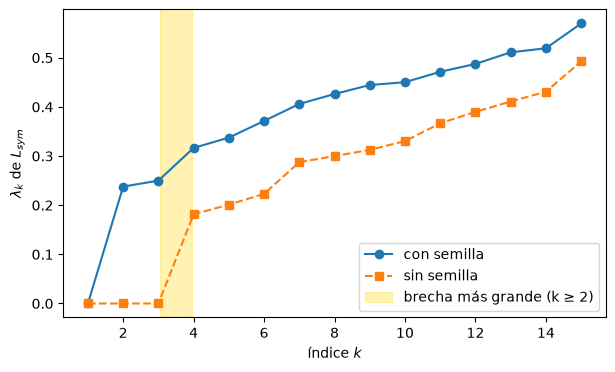

In [8]:
val, vec = np.linalg.eigh(lsym(A))
val_sin = np.linalg.eigvalsh(lsym(A_sin))
print(f'lambda_2 con semilla = {val[1]:.4f}   sin semilla = {abs(val_sin[1]):.4f}')

brechas = np.diff(val[:15])
# la brecha lambda_1 -> lambda_2 sólo dice que la semilla une a todos (k = 1), así que se busca desde k = 2
k = int(brechas[1:].argmax()) + 2
print('brechas:', np.round(brechas, 3))
print('brecha mas grande en todo el rango: k = %d' % (brechas.argmax() + 1))
print('brecha mas grande con k >= 2: entre lambda_%d y lambda_%d  ->  k = %d' % (k, k + 1, k))

fig, ax = plt.subplots(figsize=(7, 4))
for v, m, et in [(val[:15], 'o-', 'con semilla'), (val_sin[:15], 's--', 'sin semilla')]:
    ax.plot(range(1, len(v) + 1), v, m, label=et)
ax.axvspan(k + 0.05, k + 0.95, color='gold', alpha=0.3, label='brecha más grande (k ≥ 2)')
ax.set_xlabel('índice $k$')
ax.set_ylabel(r'$\lambda_k$ de $L_{sym}$')
ax.legend()
fig.savefig('figs/espectro.png', dpi=200, bbox_inches='tight')
plt.show()

$\lambda_2$ de $L_{sym}$ vale **0.2378 con la semilla y 0 sin ella**, lo que cuadra con el inciso anterior: sin la semilla el grafo se parte en tres componentes y $\lambda_2 = \lambda_3 = 0$.

**El valor de $k$.** La brecha más grande de todo el rango es la de $\lambda_1$ a $\lambda_2$ (0.238), lo que daría $k = 1$. Pero esa brecha sólo dice que la semilla une a todos, y una sola comunidad no separa nada, así que se buscó la brecha más grande a partir de $k = 2$. Esa es la de $\lambda_3 = 0.250$ a $\lambda_4 = 0.317$ (0.067), así que **$k = 3$**, justo el número de componentes que quedan sin la semilla.

**Por qué con la semilla es conexo.** Por construcción, todos los nodos entraron al grafo en el paso (b) porque comparten al menos una película con Margot Robbie, así que todos tienen una arista hacia ella y cualquier par de actores queda conectado a través de ella. Por eso hay un solo valor propio cero.

**Por qué aun así hay brecha.** El valor propio cero sólo cuenta componentes exactas, pero los valores propios pequeños miden qué tan fácil es partir el grafo: $\lambda_2$ es pequeño cuando existe un corte que separa dos grupos cortando pocas aristas en relación con su volumen. Los dos grupos de cuatro actores sólo se tocan con el resto a través de la semilla, así que cada uno se puede separar cortando cuatro aristas. Eso es lo que hace que $\lambda_2$ y $\lambda_3$ queden juntos y por debajo del resto. En otras palabras, el grafo está conectado, pero casi se desarma en tres pedazos, y al quitar la semilla ese "casi" se vuelve exacto. La brecha no es muy grande porque cada actor de esos grupos tiene grado 4 y una de esas cuatro aristas va a la semilla, así que una cuarta parte de su volumen sale del grupo.

### (c) Clustering espectral

comunidad 0:
  82 actores | mayor grado: Margot Robbie (89), Colin Farrell (17), Nicole Kidman (16)
  pelis: The Wolf of Wall Street (2013) x5 | The Suicide Squad (2021) x5 | About Time (2013) x5
comunidad 1:
  4 actores | mayor grado: Christian Radford (4), Matt Flannagan (4), Anna-Lisa Horton (4)
  pelis: I.C.U. (2009) x4 | Come and Get Me (2011) x1 | Tempted (2003) x1
comunidad 2:
  4 actores | mayor grado: Kazuya Wright (4), Lexie Symon (4), Ozzie Devrish (4)
  pelis: Vigilante (2008) x4 | The Dark Lurking (2010) x1


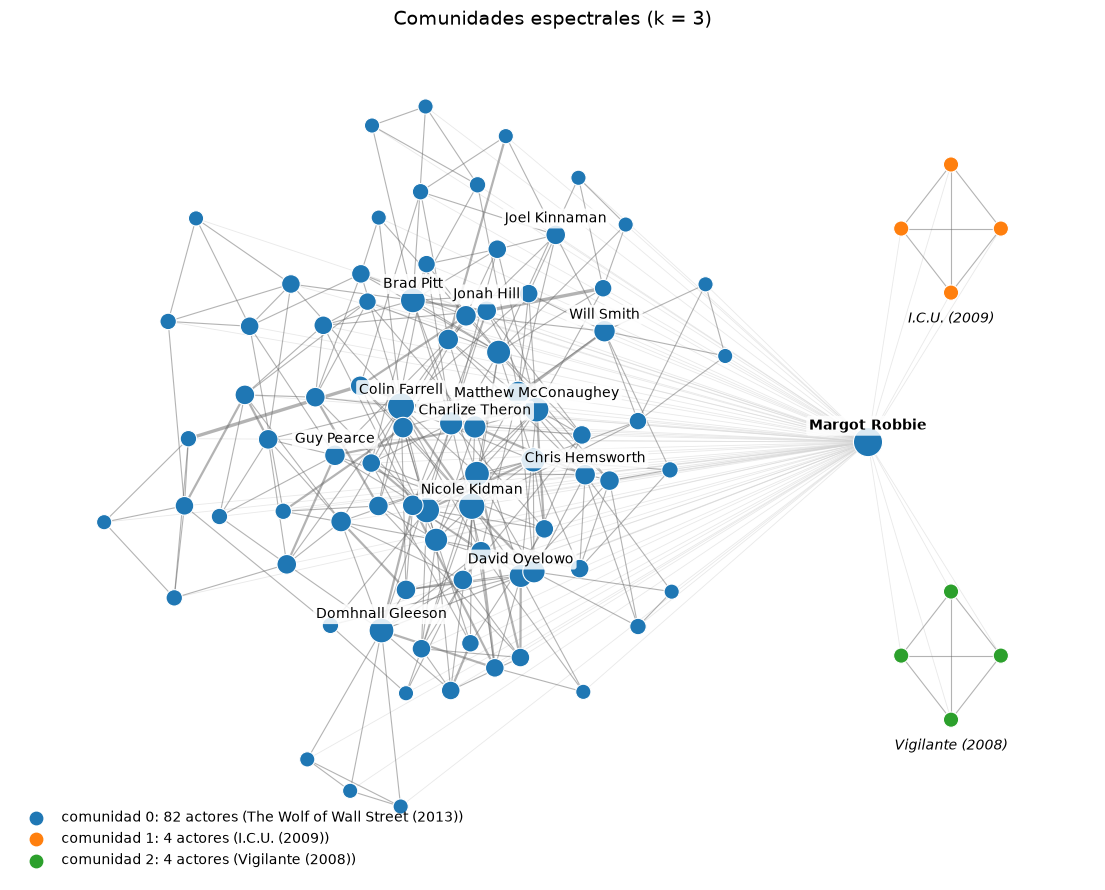

In [9]:
grado_id = dict(zip(ids, grado))


def resumen(miembros):
    top = sorted(miembros, key=grado_id.get, reverse=True)[:3]
    pelis = Counter(m for m, n in elenco.items() for _ in n & miembros).most_common(3)
    print(f'  {len(miembros)} actores | mayor grado:', ', '.join(f'{g.nodes[a]} ({grado_id[a]})' for a in top))
    print('  pelis:', ' | '.join(f'{titulos[m]} x{c}' for m, c in pelis))


U = vec[:, :k]
U = U / np.linalg.norm(U, axis=1, keepdims=True)
etiquetas = KMeans(k, n_init=10, random_state=SEMILLA_KMEANS).fit_predict(U)
for c in range(k):
    print(f'comunidad {c}:')
    resumen({ids[i] for i in np.flatnonzero(etiquetas == c)})

leyenda = []
for c in range(k):
    mi = {ids[i] for i in np.flatnonzero(etiquetas == c)}
    m = Counter(m for m, n in elenco.items() for _ in n & mi).most_common(1)[0][0]
    leyenda.append(f'comunidad {c}: {len(mi)} actores ({titulos[m]})')
dibujar(etiquetas, leyenda, 'grafo_comunidades.png', f'Comunidades espectrales (k = {k})')

Las comunidades sí corresponden a algo real: separan el **inicio de su carrera en Australia** de su carrera en Hollywood.

- **Comunidad 1 (4 actores):** el elenco de *I.C.U.* (2009).
- **Comunidad 2 (4 actores):** el elenco de *Vigilante* (2008).
- **Comunidad 0 (82 actores):** todo lo demás, desde *The Wolf of Wall Street* (2013) hasta *A Big Bold Beautiful Journey* (2025), con Margot Robbie, Colin Farrell y Nicole Kidman como los de mayor grado.

*I.C.U.* y *Vigilante* son películas australianas de bajo presupuesto que hizo antes de llegar a Hollywood, y sus elencos no volvieron a coincidir con nadie más del grafo. Son exactamente las dos componentes pequeñas que aparecen al quitar la semilla. La segunda y la tercera película más repetidas en esas comunidades salen sólo una vez, lo que confirma que ese grupo de actores sólo se juntó una vez.

Dentro de la comunidad grande no se ve una división clara con $k = 3$: las brechas que siguen son todas muy parecidas (entre 0.02 y 0.035), así que esa parte del grafo no tiene comunidades tan marcadas. Lo que sí la separa se ve con el vector de Fiedler del siguiente inciso.

### (d) Vector de Fiedler

In [10]:
_, comp = bfs_componentes(A_sin)
grande = np.flatnonzero(comp == np.bincount(comp).argmax())
Ag = A_sin[np.ix_(grande, grande)]
fiedler = np.linalg.eigh(lsym(Ag))[1][:, 1]
lado = fiedler >= 0
cruce = Ag[np.ix_(lado, ~lado)]
print(f'componente mas grande sin la semilla: {len(grande)} nodos -> {lado.sum()} / {(~lado).sum()}')
print(f'aristas que cruzan: {(cruce > 0).sum()} (peso total {cruce.sum():.0f})')
for s, nombre in [(lado, 'positivo'), (~lado, 'negativo')]:
    print(f'lado {nombre}:')
    resumen({ids_sin[i] for i in grande[s]})

componente mas grande sin la semilla: 81 nodos -> 46 / 35
aristas que cruzan: 49 (peso total 50)
lado positivo:
  46 actores | mayor grado: Colin Farrell (17), Nicole Kidman (16), Samuel L. Jackson (15)
  pelis: The Suicide Squad (2021) x4 | Focus (2015) x4 | Suicide Squad (2016) x4
lado negativo:
  35 actores | mayor grado: Domhnall Gleeson (14), Brad Pitt (14), Christian Bale (14)
  pelis: The Wolf of Wall Street (2013) x4 | About Time (2013) x4 | Babylon (2022) x4


La componente más grande sin la semilla tiene 81 actores, y el signo del vector de Fiedler la parte en **46 y 35**. Cruzan **49 de sus 269 aristas** (18 %), con un peso total de 50.

El corte no es por década, porque los dos lados tienen películas de 2013 a 2025. Lo que separa es **con quién comparten elenco** las películas de Margot Robbie:

- **Lado positivo (46):** el universo de Harley Quinn (*Suicide Squad*, *The Suicide Squad* y *Birds of Prey*) y las películas que se conectan con ese grupo, como *Focus*, donde también sale Will Smith. Del mismo lado quedan *I, Tonya*, *Mary Queen of Scots*, *Bombshell*, *Terminal*, *Dreamland* y *A Big Bold Beautiful Journey*. Los de mayor grado son Colin Farrell, Nicole Kidman y Samuel L. Jackson.
- **Lado negativo (35):** dos grupos que comparten actores entre sí. Uno es el de Domhnall Gleeson, que sale con ella en *About Time*, *Peter Rabbit* 1 y 2 y *Goodbye Christopher Robin*. El otro es el del Hollywood de los directores grandes, con *The Wolf of Wall Street*, *Once Upon a Time... in Hollywood* y *Babylon*, unidas por Brad Pitt y Leonardo DiCaprio. Del mismo lado quedan *Amsterdam* (Christian Bale) y *Barbie*.

Algunas películas quedan repartidas entre los dos lados (*The Legend of Tarzan*, *Whiskey Tango Foxtrot* y *Z for Zachariah*), porque el corte es sobre actores y no sobre películas: sus elencos tienen actores que trabajan más con un lado que con el otro.

### (e) Centralidad

In [11]:
w, V = np.linalg.eigh(A)
centralidad = np.abs(V[:, np.abs(w).argmax()])
print('top 5 grado:      ', nombres[np.argsort(grado)[::-1][:5]].tolist())
print('top 5 eigenvector:', nombres[np.argsort(centralidad)[::-1][:5]].tolist())
ref = nx.eigenvector_centrality_numpy(G, weight='weight')
assert np.allclose(centralidad / centralidad.sum(), np.array([ref[i] for i in range(len(ids))]) / sum(ref.values()))

top 5 grado:       ['Margot Robbie', 'Colin Farrell', 'Nicole Kidman', 'Samuel L. Jackson', 'Brad Pitt']
top 5 eigenvector: ['Margot Robbie', 'Domhnall Gleeson', 'James Corden', 'Rose Byrne', 'Nicole Kidman']


Las dos listas comparten a Margot Robbie y a Nicole Kidman, pero el resto cambia:

| | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Grado | Margot Robbie | Colin Farrell | Nicole Kidman | Samuel L. Jackson | Brad Pitt |
| Vector propio | Margot Robbie | Domhnall Gleeson | James Corden | Rose Byrne | Nicole Kidman |

**Qué mide cada una.** El grado cuenta con cuántos actores distintos ha trabajado alguien, sin importar quiénes son. La centralidad de vector propio cumple $Ax = \lambda_{\max} x$, es decir, $x_i \propto \sum_j A_{ij} x_j$: un actor es central si trabaja mucho con actores que a su vez son centrales. Además usa los pesos, así que repetir varias películas con el mismo actor cuenta más. Como el grafo con la semilla es conexo y $A$ no tiene entradas negativas, por Perron–Frobenius ese vector tiene todas sus entradas del mismo signo, y por eso se toma su valor absoluto.

**Por qué cambian.** En este grafo el actor más central es, por mucho, la semilla, así que la centralidad termina premiando a quien más películas repite con ella. Domhnall Gleeson comparte cuatro películas con Margot Robbie, James Corden tres (*Peter Rabbit* 1 y 2 y *Flopsy Turvy*) y Rose Byrne dos, y entre ellos también se repiten. James Corden tiene grado 7 y aun así queda tercero. En cambio Colin Farrell, Nicole Kidman y Samuel L. Jackson tienen grado alto porque salieron con muchos actores distintos, pero cada uno comparte una sola película con ella. En otras palabras, el grado mide qué tan amplia es la red de un actor y la centralidad de vector propio mide qué tan cerca está del centro del grafo.

## I.7 El puente: $A = BB^\top$

In [12]:
pelis = list(elenco)
fila = {n: i for i, n in enumerate(ids)}
B = np.zeros((len(ids), len(pelis)))
for j, m in enumerate(pelis):
    for n in elenco[m]:
        B[fila[n], j] = 1

K = B @ B.T
fuera = ~np.eye(len(ids), dtype=bool)
assert np.array_equal(K[fuera], A[fuera])
print('B:', B.shape, '  BB^T coincide con A fuera de la diagonal')
print('diagonal de BB^T (primeros 5):', {str(nombres[i]): int(K[i, i]) for i in np.argsort(-K.diagonal())[:5]})

B: (90, 2429)   BB^T coincide con A fuera de la diagonal
diagonal de BB^T (primeros 5): {'Samuel L. Jackson': 108, 'Bill Nighy': 77, 'Christoph Waltz': 76, 'Nicole Kidman': 74, 'John Lithgow': 72}


$B$ tiene 90 filas (actores) y 2 429 columnas (todas las películas que cuentan para al menos un actor del grafo), y $BB^\top$ coincide con $A$ fuera de la diagonal, que es lo que comprueba el `assert`.

**La diagonal.** $(BB^\top)_{aa} = \sum_m B_{am}^2 = \sum_m B_{am}$, que es el número de películas que cuentan para el actor $a$ (dentro de la ventana y con order < 5). Las más grandes son las de Samuel L. Jackson (108), Bill Nighy (77) y Christoph Waltz (76). En $A$ la diagonal es cero porque un actor no tiene arista consigo mismo.

**La analogía.** En la Parte 1 el peso del bosque es $w_i(x) = \frac{1}{T}\sum_t \frac{\mathbb{1}\{x_i \text{ cae en la misma hoja que } x\}}{n_{\text{hoja}}}$. Si se arma una matriz $Z$ de filas por hojas, con $Z_{i\ell} = 1$ si la fila $i$ cae en la hoja $\ell$, entonces $ZZ^\top$ cuenta en cuántos árboles caen juntas dos filas, que es $T$ veces la proximidad de 1.6. Es exactamente la misma construcción que $BB^\top$: las filas hacen el papel de los actores y cada hoja de cada árbol el de una película. Dos actores se parecen si salen juntos en muchas películas, y dos filas se parecen si caen juntas en muchas hojas. Hay dos diferencias. La primera es que en el bosque cada fila cae en exactamente una hoja por árbol, así que la diagonal de $ZZ^\top$ es $T$ para todas, mientras que aquí cada actor tiene su propio número de películas. La segunda es que el bosque divide entre el tamaño de la hoja, así que caer juntos en una hoja chica pesa más; aquí no hace falta porque todas las películas tienen a lo más 5 actores. Lo que se hizo con el espectro de $A$, buscar comunidades y cortes con pocas aristas, es lo mismo que hace Sudjianto con el kernel del bosque [2]: una región mal conectada del kernel es una región donde la predicción se apoya en pocas filas, igual que *I.C.U.* y *Vigilante* son pedazos del grafo que sólo cuelgan de la semilla.